# 02 · Data preparation

Builds the tables every later notebook uses: one row per slice for train and test, with its stack and its place in it, and one row per series with the labels and the cross-validation fold. Then the image store: every slice in Hounsfield units, in the format chosen in section 6. Each section shows the data and ends with key findings.

**Contents**
1. Labels
2. Slice metadata from the DICOM headers
3. Stacks and slice positions
4. Folds
5. DICOM to Hounsfield units
6. Choosing the storage format
7. Saving the tables and the images

Needs the header table of `scripts/extract_dicom_headers.py`; for section 6 the results of `scripts/benchmark_storage.py`, for section 7 the output of `scripts/prepare_data.py`.

In [1]:
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom

from pe.data.dicom import HU_MIN, read_hu
from pe.data.prepare import (IMAGE_LABEL, INFO_LABELS, LOCATION, N_FOLDS, SEED, SERIES_LABELS, TYPE, add_stacks, iterative_folds,
                             load_labels, slice_table, stratification_targets)
from pe.data.windows import WINDOWS, window
from pe.paths import REPO_ROOT, load_paths

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
DATA_DIR, PROCESSED = paths["raw_data_dir"], paths["processed_data_dir"]
assert DATA_DIR.exists(), f"data not found: {DATA_DIR}"

headers = pd.read_csv(PROCESSED / "dicom_headers.csv", dtype=str, keep_default_na=False)
print(f"header table: {len(headers):,} files")

header table: 1,937,447 files


## 1. Labels

`train.csv` has one row per slice, with the 13 series labels repeated on every slice of the series (01, 2.1). 01 found no repeated row and no broken rule (01, 2.2), so nothing is dropped. We split it into the slice label per image and one row per series:

In [2]:
image_labels, series_labels = load_labels(DATA_DIR / "train.csv")
print(f"slice labels: {len(image_labels):,} | series: {len(series_labels):,} | missing values: {image_labels.isna().sum() + series_labels.isna().sum().sum()}")
series_labels.head(3)

slice labels: 1,790,594 | series: 7,279 | missing values: 0


,negative_exam_for_pe,indeterminate,rightsided_pe,leftsided_pe,central_pe,rv_lv_ratio_gte_1,rv_lv_ratio_lt_1,chronic_pe,acute_and_chronic_pe,qa_motion,qa_contrast,flow_artifact,true_filling_defect_not_pe
StudyInstanceUID,,,,,,,,,,,,,
0003b3d648eb,1,0,0,0,0,0,0,0,0,0,0,0,0
000f7f114264,1,0,0,0,0,0,0,0,0,0,0,0,0
00102474a2db,1,0,0,0,0,0,0,0,0,0,0,0,0


### 1.1 Key findings

- **1,790,594 slice labels and 7,279 train series** with 13 series labels each (9 scored, 4 not scored), no missing value.

## 2. Slice metadata from the DICOM headers

We keep the header fields that later sections need:

| Columns | What for |
|---|---|
| `image`, `series`, `path`, `split` | the slice and its series (`series` is the `StudyInstanceUID`, the id of the submission) |
| `instance` | `InstanceNumber`: the order in which the scanner wrote the slices (section 3.1) |
| `thickness`, `pixel_spacing`, `stack_key` | slice thickness and pixel spacing (mm); slice thickness, pixel spacing, kernel and plane together tell stacks apart (section 3.1) |
| `pos`, `tilt` | the position along the slice normal (mm) and the angle to an axial plane: the order of the slices (section 3) |
| `reversed` | the image has its rows or columns the other way round (01, 3.5); `read_hu` flips it (section 5) |
| `writer`, `group` | the software that wrote the file and the storage group (01, 3.3): the folds are balanced on the group (section 4) |

In [3]:
slices = slice_table(headers)
slices[IMAGE_LABEL] = slices["image"].map(image_labels).astype("Int8")
tables = {"train": image_labels.index, "test": pd.Index(pd.read_csv(DATA_DIR / "test.csv")["SOPInstanceUID"])}
for split, csv_images in tables.items():
    ours = slices.loc[slices["split"] == split, "image"]
    print(f"{split}: {len(ours):,} slices, {len(csv_images):,} csv rows | no duplicates: {ours.is_unique and csv_images.is_unique} | same images: {set(ours) == set(csv_images)}")
slices.head(3)

train: 1,790,594 slices, 1,790,594 csv rows | no duplicates: True | same images: True


test: 146,853 slices, 146,853 csv rows | no duplicates: True | same images: True


,image,split,series,path,instance,writer,group,thickness,pixel_spacing,pos,tilt,reversed,stack_key,pe_present_on_image
0,14605bcc564c,train,0003b3d648eb,train/0003b3d648eb/d2b2960c2bbf/14605bcc564c.dcm,1,dcm4che-1.4.35,dcm4che-1.4.35 | explicit VR | 16 bit | signed...,1.25,0.871094,-320.50,0.0,False,"1.250000 | 0.871094\0.871094 | STANDARD | 0.0,...",0
1,d0849d3b6507,train,0003b3d648eb,train/0003b3d648eb/d2b2960c2bbf/d0849d3b6507.dcm,2,dcm4che-1.4.35,dcm4che-1.4.35 | explicit VR | 16 bit | signed...,1.25,0.871094,-319.25,0.0,False,"1.250000 | 0.871094\0.871094 | STANDARD | 0.0,...",0
2,18928b724b69,train,0003b3d648eb,train/0003b3d648eb/d2b2960c2bbf/18928b724b69.dcm,3,dcm4che-1.4.35,dcm4che-1.4.35 | explicit VR | 16 bit | signed...,1.25,0.871094,-318.00,0.0,False,"1.250000 | 0.871094\0.871094 | STANDARD | 0.0,...",0


**No patient id.** The headers carry no `PatientID`, but the data set has one study per patient ([Colak et al. 2021](https://pubs.rsna.org/doi/full/10.1148/ryai.2021200254)), and a study is one series (01, 1.2). Folds of whole series are therefore folds of whole patients.

### 2.1 Key findings

- **One row per slice: 1,790,594 train and 146,853 test**, matching `train.csv` and `test.csv` one to one.
- **Series = study = patient,** so the folds are split by series (section 4).

## 3. Stacks and slice positions

01 found irregular series: slices at the same z, gaps, several slice thicknesses or pixel spacings in one series, and an `InstanceNumber` that neither rises nor falls along z in 158 series (01, 4.2–4.4). One series, its slices in `InstanceNumber` order:

In [4]:
example = slices[slices["series"] == "0203d899bebc"]
example.iloc[[0, 1, 2, 303, 304, 305, 306, 307, -1]][["instance", "pos", "thickness", "pixel_spacing"]]

,instance,pos,thickness,pixel_spacing
17331,1,-243.250000,1.25,0.683594
17332,2,-242.449997,1.25,0.683594
17333,3,-241.649994,1.25,0.683594
17634,304,-0.850000,1.25,0.683594
17635,305,-0.050000,1.25,0.683594
17636,306,-965.500000,5.00,0.683594
17637,307,-960.500000,5.00,0.683594
17638,308,-955.500000,5.00,0.683594
17755,425,-370.500000,5.00,0.683594


The scanner wrote 305 slices of 1.25 mm, then 120 of 5 mm that start again 965 mm lower and climb to −370 mm: **two stacks in one series**, a chest scan and a second one further down the body.

### 3.1 Several stacks in one series

A new stack starts, in `InstanceNumber` order, where the slice thickness, the pixel spacing, the kernel or the plane change, or where the position turns back (a second pass). A jump forward in the same direction is a gap, not a new stack (`stack_ids` in `src/pe/data/prepare.py`). How many series hold more than one stack?

In [5]:
slices = add_stacks(slices)
per_series = slices.groupby("series").agg(split=("split", "first"), n_stacks=("n_stacks", "first"))
pd.crosstab(per_series["n_stacks"], per_series["split"])

split,test,train
n_stacks,,
1,649,7121
2,1,143
3,0,10
4,0,5


What are the other stacks? Each one compared with the main stack of its series (the first axial one, below):

In [6]:
st = slices.groupby(["series", "stack"]).agg(split=("split", "first"), main=("main", "first"), n=("image", "size"), thickness=("thickness", "median"),
                                             spacing=("pixel_spacing", "median"), tilt=("tilt", "max"), low=("pos", "min"), high=("pos", "max"),
                                             positives=(IMAGE_LABEL, "sum"))
main = st[st["main"]].droplevel("stack")
other = st[~st["main"]].join(main[["thickness", "spacing", "low", "high"]], on="series", rsuffix="_main")
other["kind"] = np.select(
    [other["tilt"] > 45, other["thickness"] > other["thickness_main"], (other["spacing"] - other["spacing_main"]).abs() > 1e-3],
    ["another plane", "thicker slices", "same thickness, other field of view"], "same thickness and spacing, another pass")
other["ends below the main stack"] = other["high"] < other["high_main"] - 10
other["overlaps the main stack"] = (other["low"] < other["high_main"]) & (other["high"] > other["low_main"])
other.groupby("kind").agg(stacks=("n", "size"), series=("n", lambda s: s.index.get_level_values(0).nunique()), median_slices=("n", "median"),
                          ends_below=("ends below the main stack", "sum"), overlaps=("overlaps the main stack", "sum"))

,stacks,series,median_slices,ends_below,overlaps
kind,,,,,
another plane,1,1,1.0,1,0
"same thickness and spacing, another pass",18,15,355.5,14,17
"same thickness, other field of view",42,33,368.0,42,36
thicker slices,118,111,125.5,118,23


Which stack holds the labels? Positive slices by stack, in the train series with several stacks:

In [7]:
multi_train = st[(st["split"] == "train") & st.index.get_level_values(0).isin(per_series.index[per_series["n_stacks"] > 1])]
positive_series = multi_train.groupby(level="series")["positives"].sum() > 0
print(f"train series with several stacks: {multi_train.index.get_level_values(0).nunique()} | with a positive slice: {positive_series.sum()}")
print("positive slices in the main stack:", int(multi_train.loc[multi_train["main"], "positives"].sum()),
      "| in the other stacks:", int(multi_train.loc[~multi_train["main"], "positives"].sum()))
other_train = (slices["split"].eq("train") & ~slices["main"]).sum()
print(f"train slices in the other stacks: {other_train:,} ({other_train / slices['split'].eq('train').sum():.1%})")

near = {}
for sid in positive_series[positive_series].index:
    g = slices[slices["series"] == sid]
    others = g.loc[~g["main"], "pos"].to_numpy()
    near[sid] = sum(np.abs(others - p).min() <= 2 for p in g.loc[g[IMAGE_LABEL] == 1, "pos"])
print(f"positive slices with a slice of another stack within 2 mm: {sum(near.values())}, in {sum(n > 0 for n in near.values())} series")

train series with several stacks: 158 | with a positive slice: 43
positive slices in the main stack: 1494 | in the other stacks: 0


train slices in the other stacks: 33,928 (1.9%)


positive slices with a slice of another stack within 2 mm: 479, in 23 series


Positions against `InstanceNumber` in four series, coloured by stack (crosses: positive slices). Each point is a slice: a straight line is one pass, a turn or a change of settings starts a new stack (a jump in the same direction stays in the stack), and within a panel a steeper line means more mm per slice:

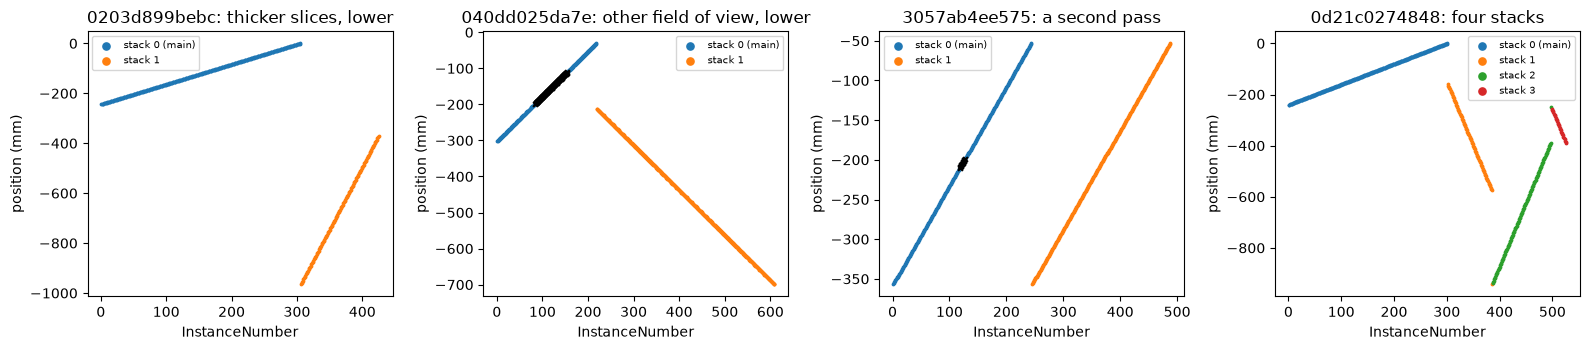

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (sid, title) in zip(axes, [("0203d899bebc", "thicker slices, lower"), ("040dd025da7e", "other field of view, lower"),
                                   ("3057ab4ee575", "a second pass"), ("0d21c0274848", "four stacks")]):
    g = slices[slices["series"] == sid]
    for k, s in g.groupby("stack"):
        ax.scatter(s["instance"], s["pos"], s=3, label=f"stack {k}" + (" (main)" if s["main"].iloc[0] else ""))
    pos = g[g[IMAGE_LABEL] == 1]
    ax.scatter(pos["instance"], pos["pos"], s=12, marker="x", c="k")
    ax.set(title=f"{sid}: {title}", xlabel="InstanceNumber", ylabel="position (mm)")
    ax.legend(fontsize=7, markerscale=3)
plt.tight_layout()

What the stacks show: one series for each number of stacks, with the slices of each stack at 5, 35, 65 and 95% of its length in the PE window:

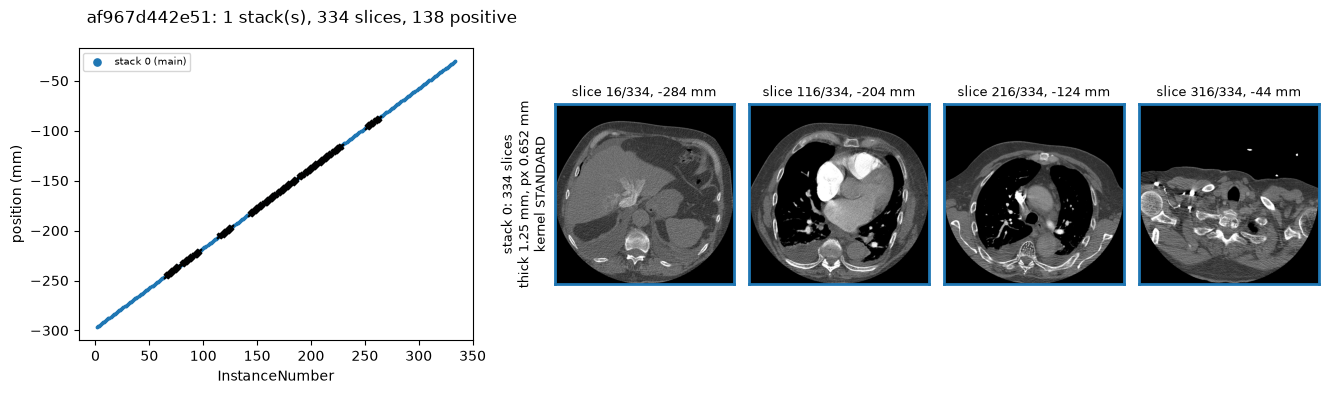

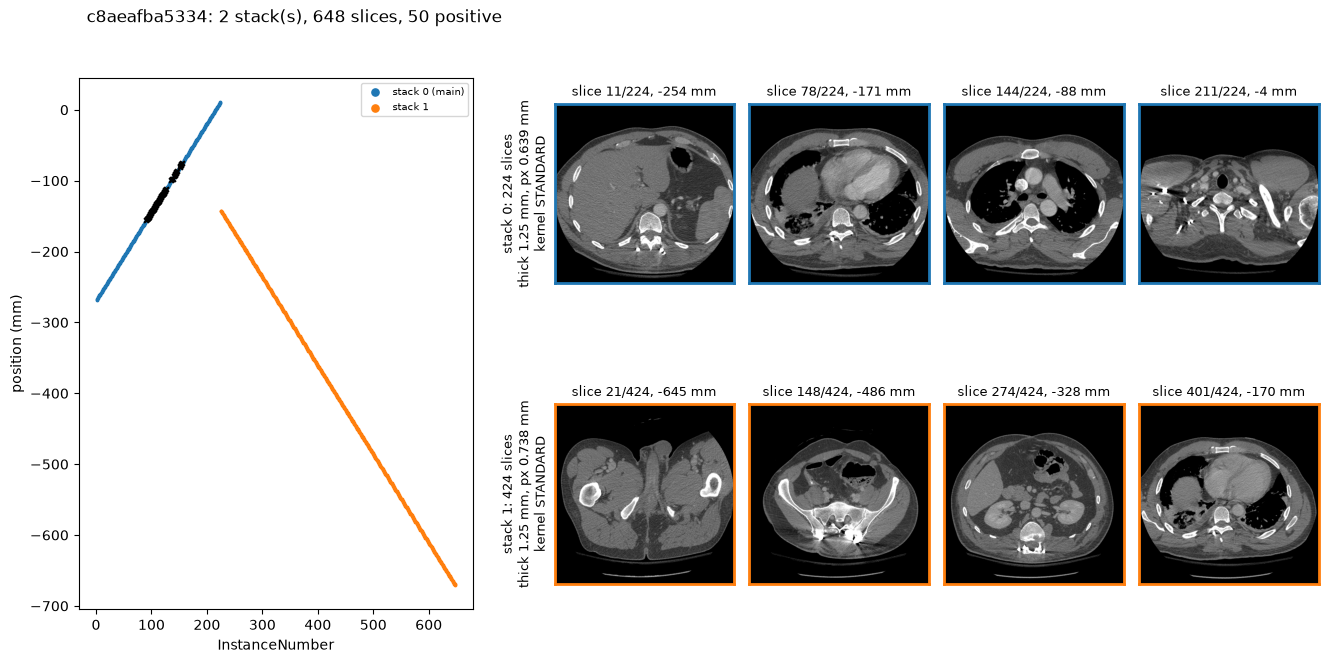

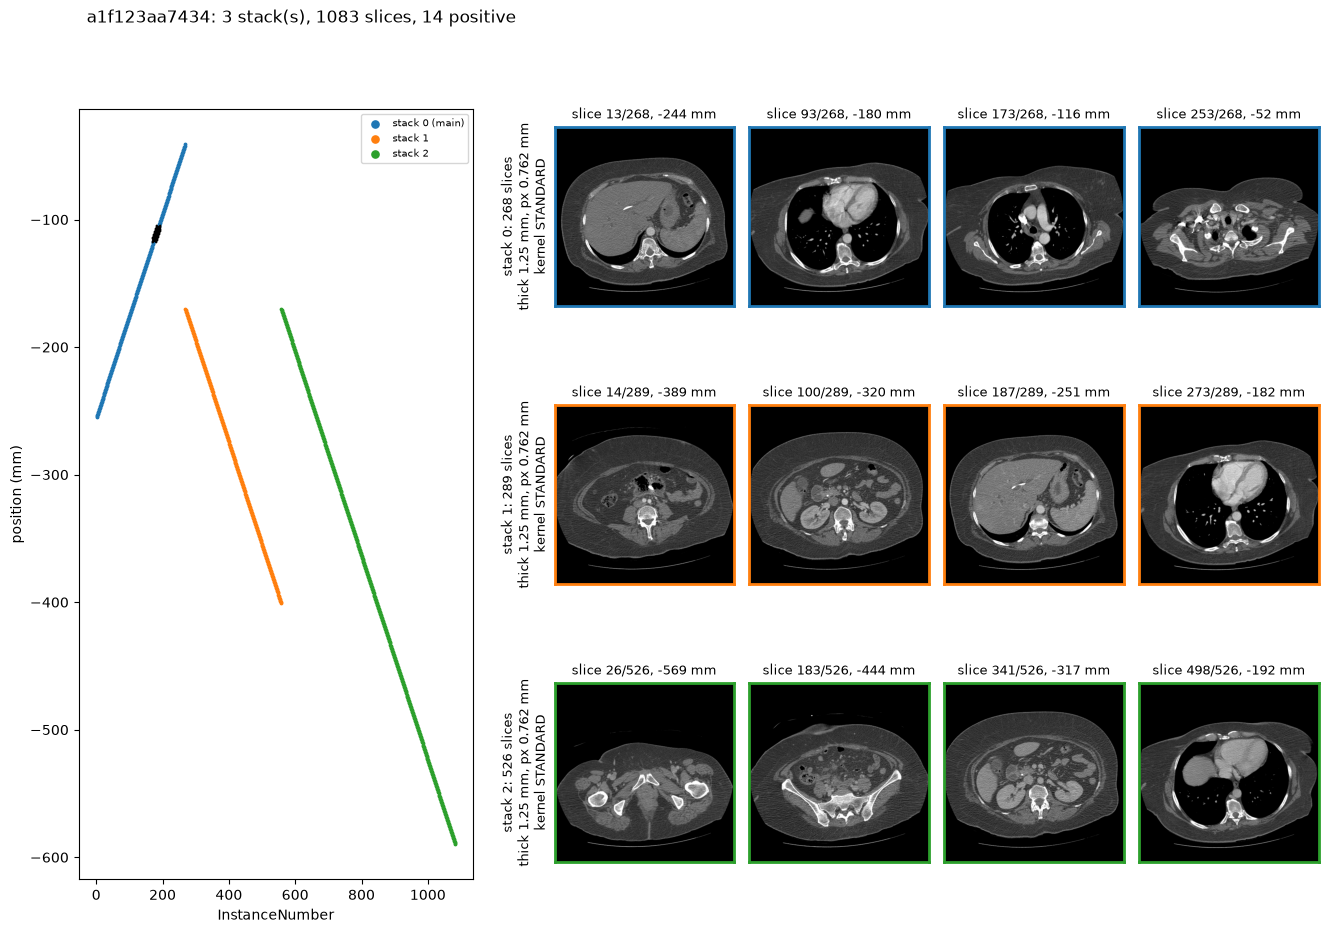

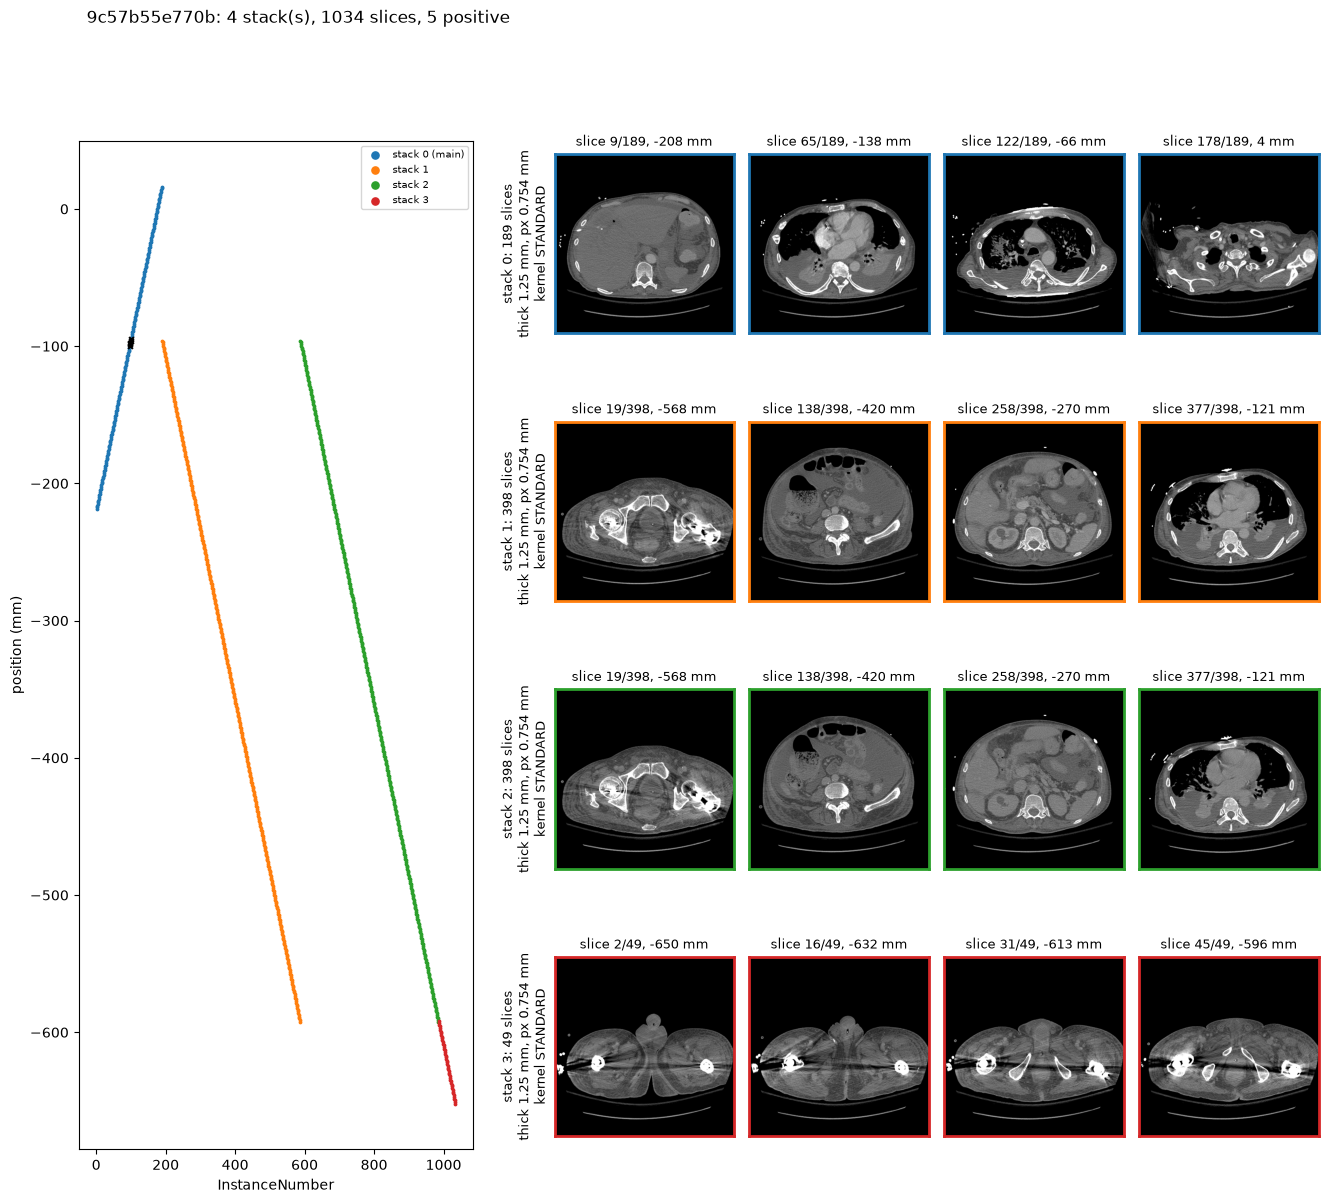

In [9]:
kernels = headers.set_index("SOPInstanceUID")["ConvolutionKernel"]
for sid in ["af967d442e51", "c8aeafba5334", "a1f123aa7434", "9c57b55e770b"]:
    g = slices[slices["series"] == sid].sort_values(["stack", "slice"])
    stacks = list(g["stack"].unique())
    fig = plt.figure(figsize=(16, 3.1 * len(stacks) + 0.7))
    grid = fig.add_gridspec(len(stacks), 6, width_ratios=[2.2, 0.28, 1, 1, 1, 1], wspace=0.08, hspace=0.3)
    ax = fig.add_subplot(grid[:, 0])
    for row, k in enumerate(stacks):
        s = g[g["stack"] == k]
        ax.scatter(s["instance"], s["pos"], s=3, color=f"C{k}", label=f"stack {k}" + (" (main)" if s["main"].iloc[0] else ""))
        for col, q in enumerate([0.05, 0.35, 0.65, 0.95]):
            r = s.iloc[int(q * (len(s) - 1))]
            a = fig.add_subplot(grid[row, col + 2])
            a.imshow(window(read_hu(DATA_DIR / r["path"]), *WINDOWS["pe"]), cmap="gray", vmin=0, vmax=1)
            a.set(xticks=[], yticks=[])
            a.set_title(f"slice {r['slice']}/{r['n_slices']}, {r['pos']:.0f} mm", fontsize=9)
            for side in a.spines.values():
                side.set_color(f"C{k}")
                side.set_linewidth(2)
            if col == 0:
                a.set_ylabel(f"stack {k}: {len(s)} slices\nthick {r['thickness']} mm, px {r['pixel_spacing']:.3f} mm\nkernel {kernels[r['image']]}", fontsize=9)
    pos = g[g[IMAGE_LABEL] == 1]
    ax.scatter(pos["instance"], pos["pos"], s=12, marker="x", c="k")
    ax.set(xlabel="InstanceNumber", ylabel="position (mm)")
    ax.legend(fontsize=7, markerscale=3)
    fig.suptitle(f"{sid}: {len(stacks)} stack(s), {len(g)} slices, {len(pos)} positive", x=0.13, ha="left")
    plt.show()

**Decision**
- **Every slice stays,** since each needs a prediction. `stack` numbers the stacks in `InstanceNumber` order, and every per-slice column (`slice`, `n_slices`, the gaps) is counted within the stack, so neighbouring slices follow the body, apart from the gaps flagged in 3.2.
- **`main` marks the stack we take as read: the first axial stack in `InstanceNumber` order,** since no header field names it. Direct evidence: all 1,494 positive slices of the 43 positive series with several stacks are in it. Clinical logic: PE is an emergency, so its protocol is scanned first. The other stacks mostly end below it, and many overlap it.
- **The models train on the main stacks only.** Slices of the other stacks get the prediction 0, in validation and in the test. They still count in the metric: its q_i divides by all slices of a series, not by the `n_slices` of a stack.

### 3.2 Spacing within a stack

Per slice of a stack we record:

| Columns | What for |
|---|---|
| `slice`, `n_slices` | where in the stack the slice is (index from the lower end) and how many slices the stack has |
| `gap_prev`, `gap_next` | the distance (mm) to the slice below and above |
| `local_spacing` | the usual spacing around the slice (median of the five gaps around it) |
| `same_position`, `wide_gap` | another slice at the same position; a gap of more than 1.5 × the local spacing below the slice |

The spacing of the main stacks (median gap per stack, mm), and what is left of the irregular slices of 01:

In [10]:
main_slices = slices[slices["main"]]
display(main_slices.groupby(["split", "series"])["gap_prev"].median().groupby("split").describe(percentiles=[0.05, 0.5, 0.95]).round(2))
by_split = slices.groupby("split")
pd.DataFrame({
    "slices at the same position": by_split["same_position"].sum(),
    "series with such slices": slices[slices["same_position"]].groupby("split")["series"].nunique(),
    "wide gaps": by_split["wide_gap"].sum(),
    "series with a wide gap": slices[slices["wide_gap"]].groupby("split")["series"].nunique(),
}).fillna(0).astype(int).T

,count,mean,std,min,5%,50%,95%,max
split,,,,,,,,
test,650.0,1.31,0.25,0.80,1.25,1.25,2.00,3.0
train,7279.0,1.24,0.23,0.62,0.80,1.25,1.25,5.0


split,test,train
slices at the same position,0,2
series with such slices,0,1
wide gaps,0,34
series with a wide gap,0,13


In [11]:
gaps = slices[slices["wide_gap"]].groupby("series").agg(main=("main", "first"), gaps=("image", "size"), largest_mm=("gap_prev", "max"),
                                                         local_spacing=("local_spacing", "median"))
gaps.sort_values("largest_mm", ascending=False).round(2)

,main,gaps,largest_mm,local_spacing
series,,,,
0d21c0274848,False,2,368.25,5.00
b6f94efb74a4,False,1,105.00,1.25
bc855cd8bdc9,True,2,10.00,5.00
2310db914ba6,True,1,8.75,1.88
6fdc209b50b1,True,2,2.50,1.25
e4ef255fe2d2,True,1,2.50,1.25
1566fcc86bf1,True,1,2.40,0.80
0db580c64af4,True,5,2.00,1.00
90bca49335fc,True,8,1.88,0.62


**Decision:** both are kept, since neither can be repaired from the data, and flagged so that the models can use the distances.

### 3.3 Orientation

**The patient's right must be on the same side of the image in every series;** otherwise a model cannot learn `rightsided_pe` and `leftsided_pe`.

One train series has its rows and columns reversed (01, 3.5), so `read_hu` turns it by 180°. One test series is tilted by 3° with one slice in another plane (01, 3.5). The reversed series, as stored and after `read_hu` (lung window):

       slices       tilt   main
stack                          
0           1  86.860098  False
1          95   3.144800   True


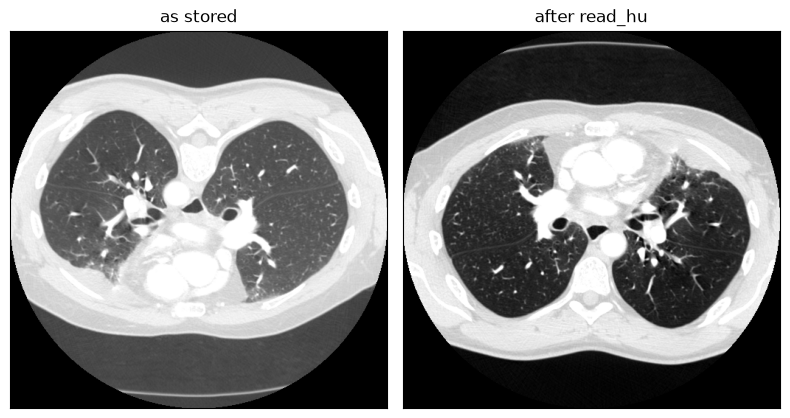

In [12]:
r = slices[(slices["series"] == "8d2e355906f2") & (slices["slice"] == 120)].iloc[0]
ds = pydicom.dcmread(DATA_DIR / r["path"])
stored = ds.pixel_array * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
for ax, img, title in [(axes[0], stored, "as stored"), (axes[1], read_hu(DATA_DIR / r["path"]), "after read_hu")]:
    ax.imshow(window(img, *WINDOWS["lung"]), cmap="gray")
    ax.set(title=title, xticks=[], yticks=[])
plt.tight_layout()
print(slices.loc[slices["series"] == "0cfc61e46f28"].groupby("stack").agg(slices=("image", "size"), tilt=("tilt", "max"), main=("main", "first")))

### 3.4 Key findings

- **159 series hold several stacks (158 train, 1 test),** 2–4 each. Of the 179 other stacks, 118 have thicker slices, 42 another field of view and 18 the same thickness and spacing; one is the slice in another plane. 175 end below the main stack, and 76 overlap it.
- **All positive labels lie in the main stack:** all 1,494 positive slices of the 43 positive series with several stacks are in it. The other stacks hold 33,928 train slices (1.9%).
- **A 0 on another stack most likely means "not read", not "no PE":** in 23 of those series, 479 positive slices have a slice of another stack within 2 mm, and none of those is labelled positive.
- **This explains the irregularities of 01:** the slices at the same z, most gaps and the mixed thicknesses and spacings were stacks side by side. What remains: 2 slices at the same position in one series, and 34 wide gaps in 13 train series (31 of 1.4–10 mm in 11 main stacks, most likely missing slices), flagged.
- **The visible test is more regular:** one series with several stacks, no wide gap. Its main stacks are more often thick (95th percentile of the median spacing 2.0 mm, train 1.25 mm).
- **The reversed series is a prone scan;** `read_hu` flips it to the usual orientation (front up, the patient's right on the left). The tilted test series is one main stack of 95 slices, sorted along its normal.

## 4. Folds

How do we split the 7,279 train series so that every fold is a fair test? The folds hold whole series (section 2), and every fold should have the same mix of what changes the difficulty:
- the rare labels: acute and chronic (145 series), indeterminate (157), chronic (292), central (401) (01, 2.4);
- the storage group, since the groups differ in positive rate from 6% to 73% (01, 3.5).

Each series gets a 0/1 vector: the nine series labels, positive, the two QA labels and its storage group. **Iterative stratification** ([Sechidis et al. 2011](https://doi.org/10.1007/978-3-642-23808-6_10)) deals the series out label by label, the rarest first, each to the fold that most lacks it.

In [13]:
series = slices.groupby("series").agg(split=("split", "first"), group=("group", "first"), n_slices=("image", "size"),
                                      n_stacks=("n_stacks", "first")).join(series_labels)
train_series = series[series["split"] == "train"].copy()
y = stratification_targets(train_series)
train_series["fold"] = iterative_folds(y.to_numpy(), N_FOLDS, SEED)
print(f"stratified on {y.shape[1]} columns ({y.shape[1] - len(SERIES_LABELS) - 3} storage groups)")

stratified on 21 columns (9 storage groups)


Are the folds alike in what we balanced?

In [14]:
by_fold = train_series.groupby("fold")
positive = 1 - train_series["negative_exam_for_pe"] - train_series["indeterminate"]
group_share = pd.crosstab(train_series["fold"], train_series["group"], normalize="index") * 100
pd.DataFrame({"series": by_fold.size(), "slices": by_fold["n_slices"].sum(), "% positive": (positive.groupby(train_series["fold"]).mean() * 100).round(1),
              **{c: by_fold[c].sum().astype(int) for c in ["indeterminate", "central_pe", "chronic_pe", "acute_and_chronic_pe", "rv_lv_ratio_gte_1"]},
              "several stacks": by_fold["n_stacks"].apply(lambda s: (s > 1).sum()),
              "largest group share gap (points)": (group_share - group_share.mean()).abs().max(axis=1).round(1)})

,series,slices,% positive,indeterminate,central_pe,chronic_pe,acute_and_chronic_pe,rv_lv_ratio_gte_1,several stacks,largest group share gap (points)
fold,,,,,,,,,,
0,1460,360779,30.6,31,81,59,29,188,29,0.2
1,1457,356261,30.4,32,80,58,29,188,28,0.0
2,1460,359137,30.6,31,80,58,29,188,37,0.2
3,1447,355078,29.9,32,80,59,29,188,34,0.4
4,1455,359339,30.4,31,80,58,29,188,30,0.1


### 4.1 Key findings

- **5 folds of whole series,** 1,447–1,460 series and 355,078–360,779 slices each.
- **What we balanced is equal across folds:** 29.9–30.6% positive series; each rare label differs by at most one series (indeterminate 31–32, central 80–81, chronic 58–59, acute and chronic 29); the storage group shares stay within 0.4 points of their mean.
- Scores can still differ between folds: the image content, the label noise and the training randomness are not controlled.

## 5. DICOM to Hounsfield units

A DICOM file stores raw pixel values; HU = value × slope + intercept. 01 found where this needs care. `read_hu` in `src/pe/data/dicom.py` handles each case:

| Problem (01) | What `read_hu` does |
|---|---|
| Files stored as unsigned integers: adding a negative intercept wraps around | casts the values to float before the rescale |
| The padding outside the scanned circle is −3024, −2048 or none, depending on the group, and metal reaches 10,466 HU (01, 6.1–6.3) | clips to [−1024, 3071] HU |
| One series has its rows and columns reversed (01, 3.5) | flips it to the common orientation |
| 6.6% of the train files are JPEG lossless (01, 1.2) | decodes them with GDCM or pylibjpeg (in `requirements.txt`) |
| Every image is 512 × 512 (01, 3.5), but the hidden test may differ | pads a non-square image with air and resizes it to 512 × 512 |

The unit tests in `tests/test_dicom.py` check each step on small synthetic files whose correct result is known:

In [15]:
tests = subprocess.run([sys.executable, "-m", "pytest", "tests/test_dicom.py", "-q", "--color=no", "-p", "no:cacheprovider"],
                       cwd=REPO_ROOT, capture_output=True, text=True)
print(tests.stdout.strip().splitlines()[-1])

13 passed, 3 warnings in 0.63s


Does it give the right values on real files? One random slice from the middle of the main stack (30–70% of its length, where the lungs are) of up to 20 series per storage group. The lung tissue (the median of the pixels between −1000 and −500 HU) at −950 to −850 HU; the soft tissue (the median of the pixels between −100 and 150 HU, fat and muscle together) at 0–50 HU. The last column is the share of pixels at exactly −1024 HU.

In [16]:
group_of = series["group"]
middle = slices[slices["main"] & (slices["slice"] / slices["n_slices"]).between(0.3, 0.7)]
sample = middle.groupby("series").sample(1, random_state=SEED).assign(group=lambda d: d["series"].map(group_of))
sample = pd.concat(g.sample(min(20, len(g)), random_state=SEED) for _, g in sample.groupby("group"))
rows = []
for _, r in sample.iterrows():
    hu = read_hu(DATA_DIR / r["path"])
    rows.append({"group": r["group"], "lung HU": np.median(hu[(hu > -1000) & (hu < -500)]), "soft tissue HU": np.median(hu[(hu > -100) & (hu < 150)]),
                 "% at -1024": (hu == HU_MIN).mean() * 100})
checked = pd.DataFrame(rows).groupby("group").agg(slices=("lung HU", "size"), lung_hu=("lung HU", "median"), soft_tissue_hu=("soft tissue HU", "median"),
                                                  pct_at_minus_1024=("% at -1024", "median"))
checked.round(1)

,slices,lung_hu,soft_tissue_hu,pct_at_minus_1024
group,,,,
(none) | implicit VR | 12 bit | unsigned | -1024,20,-910.0,2.5,4.4
(none) | implicit VR | 16 bit | signed | -1024,20,-880.5,8.0,21.4
(none) | implicit VR | 16 bit | signed | 0,20,-861.5,15.5,23.5
PYDICOM 1.2.2 | implicit VR | 12 bit | unsigned | -1024,20,-942.0,3.5,0.2
dcm4che-1.4.35 | explicit VR | 12 bit | unsigned | -1024,3,-937.0,26.0,2.7
dcm4che-1.4.35 | explicit VR | 16 bit | signed | -1024,20,-884.0,4.5,21.4
dcm4che-1.4.37 | JPEG lossless | 16 bit | signed | -1024,20,-885.5,5.0,21.4
dcm4che-1.4.37 | explicit VR | 16 bit | signed | -1024,20,-856.0,3.5,21.4
dcm4che-1.4.38 | explicit VR | 12 bit | unsigned | -1024,20,-917.5,-1.0,0.7


### 5.1 Key findings

- **`read_hu` passes its 13 unit tests and gives the expected values in every storage group:** lung tissue at −942 to −856 HU, soft tissue at −1 to 26 HU (the lowest just under the expected range; one group has only 3 series). The JPEG lossless files decode to the same HU as the plain ones (unit test).
- **A trace of the group remains after clipping:** in the 16-bit groups 21–24% of the pixels sit at exactly −1024 HU (the padding), in the 12-bit groups 0.2–4%. In every window of 01, 6.2 −1024 and air (−1000) are almost the same gray (at most 0.016 apart), so the windowed images hardly show it.

## 6. Choosing the storage format

Training reads every slice in every epoch, and reading the DICOM files each time is slow: they lie on a hard disk and need the steps of section 5. So we write a store once on the SSD. `scripts/benchmark_storage.py` measures the candidates of `src/pe/data/formats.py` on the main stacks of two series per storage group.

In [17]:
import json
import os

BENCH = paths["outputs_dir"] / "storage_benchmark"
bench = {f.stem: pd.read_csv(f) for f in BENCH.glob("*.csv")}
notes = json.loads((BENCH / "notes.json").read_text())
print(f"benchmark: {notes['benchmark slices']:,} slices of {notes['benchmark series']} series | free on the SSD: {notes['free GB on processed_data_dir']} GB")

benchmark: 4,570 slices of 18 series | free on the SSD: 687 GB


### 6.1 Which stores do we test?

The size of each full store:

In [18]:
sizes = bench["sizes"].set_index("name")
sizes.assign(decision={"dicom": "out: does not fit on the SSD", "npy16": "out: does not fit on the SSD", "png16": "tested", "jp2": "tested",
                       "png8x3": "out: keeps only three windows", "jpg8x3": "out: keeps only three windows, lossy"})[["format", "content", "store GB", "decision"]]

,format,content,store GB,decision
name,,,,
dicom,DICOM,HU,979.7,out: does not fit on the SSD
npy16,npy int16,HU,1016.0,out: does not fit on the SSD
png16,PNG 16-bit,HU,486.3,tested
jp2,JPEG 2000 lossless,HU,341.4,tested
png8x3,PNG 8-bit,3 windows,543.0,out: keeps only three windows
jpg8x3,JPEG,3 windows,282.3,"out: keeps only three windows, lossy"


The 8-bit stores fit, but they would fix the windows before 04 chooses the model input.

### 6.2 PNG 16-bit or JPEG 2000?

Reading from the SSD, then through 12 `DataLoader` workers (three neighbouring slices per input; one epoch over the main stacks of the train slices). The last rows are a full training step at 512 px, as a share of its speed with the data already on the GPU:

In [19]:
levels = bench["png_levels"].set_index("level")
print("PNG 16-bit at level 1, 6, 9 | KB per slice:", *levels["KB per slice"], "| decode ms:", *levels["decode ms"])
speed, loader = bench["speed"].set_index("name"), bench["loader"].set_index("name")
identical = bench["identical"].set_index("format")["files identical to the stored array"]
gpu = bench["end_to_end"].pivot(index="store", columns="backbone", values="%")
pd.DataFrame({sizes.loc[n, "format"]: {
    "store (GB)": f"{sizes.loc[n, 'store GB']:.0f}",
    "files identical to the stored array": identical[sizes.loc[n, "format"]],
    "read one slice (ms)": f"{speed.loc[n, 'cold ms']:.1f}",
    "inputs per second": f"{loader.loc[n, 'inputs/s, 12 workers']:.0f}",
    "minutes per epoch": f"{loader.loc[n, 'epoch min, 12 workers']:.0f}",
    **{f"% of GPU speed, {b}": f"{gpu.loc[n, b]:.0f}" for b in gpu.columns},
} for n in ["png16", "jp2"]})

PNG 16-bit at level 1, 6, 9 | KB per slice: 257.3 249.9 247.6 | decode ms: 2.9 2.9 2.9


,PNG 16-bit,JPEG 2000 lossless
store (GB),486,341
files identical to the stored array,"4,570 / 4,570","4,570 / 4,570"
read one slice (ms),3.8,24.4
inputs per second,822,135
minutes per epoch,36,217
"% of GPU speed, efficientnet_b3",85,38
"% of GPU speed, seresnext50_32x4d",98,48
"% of GPU speed, tf_efficientnet_b5",95,71


**Decision: PNG 16-bit HU at level 6, one file per slice, in one folder per series.** It is lossless, so every window stays open, and it keeps up with training. JPEG 2000 would save 145 GB, but it decodes 6 times slower and the GPU would wait for it. Level 6 makes the files 3% smaller than level 1, the OpenCV default, at the same reading speed.

### 6.3 Key findings

- **Size:** PNG 16-bit 486 GB and JPEG 2000 341 GB, against 980 GB for the DICOM files.
- **Speed:** PNG 16-bit reads a slice in 3.8 ms and reaches 85–98% of the GPU speed; JPEG 2000 takes 24 ms and reaches 38–71%. One epoch takes 36 against 217 minutes.

## 7. Saving the tables and the images

The later notebooks should not have to run this one again. `scripts/prepare_data.py` writes what sections 1–6 built, with the functions of `src/pe/data/prepare.py`:
- `processed_data_dir/series.csv`: one row per series; `read_series` reads it with its column types;
- `processed_data_dir/slices.csv`: one row per slice, with the pixel statistics of section 7.3; `read_slices` reads it;
- `processed_data_dir/png16/<series>/<image>.png`: every slice as PNG 16-bit, HU + 1024, level 6 (section 6).

Does the script give the same tables and images as this notebook?

### 7.1 The tables

In [20]:
from pe.data.formats import FORMATS
from pe.data.prepare import read_series, read_slices, store_path

table = read_slices(PROCESSED / "slices.csv")
series_table = read_series(PROCESSED / "series.csv").set_index("series")
columns = [c for c in slices.columns if c not in ("stack_key", "group", "writer")]
pd.testing.assert_frame_equal(table[columns], slices[columns].reset_index(drop=True), check_dtype=False)
all_series = ["split", "group", "n_slices", "n_stacks"]
pd.testing.assert_frame_equal(series_table.loc[series.index, all_series], series[all_series], check_dtype=False, check_names=False)
pd.testing.assert_frame_equal(series_table.loc[train_series.index, SERIES_LABELS + INFO_LABELS + ["fold", "group"]],
                              train_series[SERIES_LABELS + INFO_LABELS + ["fold", "group"]], check_dtype=False, check_names=False)
print(f"slices.csv: {table.shape[0]:,} rows, {table.shape[1]} columns | series.csv: {len(series_table):,} rows | both equal to this notebook")

slices.csv: 1,937,447 rows, 31 columns | series.csv: 7,929 rows | both equal to this notebook


### 7.2 The images

Is there one file per row, and no partial file? Then the pixels: does the stored image equal `read_hu` rounded to integer HU? 500 random slices and every special case: 20 slices of each storage group (the JPEG one included), the reversed series, the tilted test series, the slices at the same position and 20 slices of other stacks.

In [21]:
store = PROCESSED / "png16"
names, size, temporary = set(), 0, 0
for d in os.scandir(store):
    for e in os.scandir(d):
        names.add(f"{d.name}/{e.name}")
        size += e.stat().st_size
        temporary += e.name.endswith(".tmp")
expected = {f"{s}/{i}.png" for s, i in zip(table["series"], table["image"])}
print(f"files: {len(names):,} | one per row: {names == expected} | temporary files left: {temporary} | size: {size / 1e9:.1f} GB")
print("files the script could not decode:", int(table["body_share"].isna().sum()))

table["group"] = table["series"].map(series_table["group"])
special = pd.concat([table.groupby("group").sample(20, random_state=SEED),
                     table[table["series"] == "8d2e355906f2"].sample(20, random_state=SEED),
                     table[table["series"] == "0cfc61e46f28"], table[table["same_position"]],
                     table[~table["main"]].sample(20, random_state=SEED)])
checked = pd.concat([table.sample(500, random_state=SEED), special]).drop_duplicates("image")
same = [np.array_equal(FORMATS["png16"].decode(store_path(store, r.series, r.image).read_bytes()).astype(np.int16) + HU_MIN,
                       np.rint(read_hu(DATA_DIR / r.path))) for r in checked.itertuples()]
print(f"stored image = read_hu rounded: {sum(same):,} of {len(same):,} slices")

files: 1,937,447 | one per row: True | temporary files left: 0 | size: 486.1 GB
files the script could not decode: 0


stored image = read_hu rounded: 818 of 818 slices


### 7.3 Body and lungs

`pixel_stats` records two boxes per slice: the **body** (the largest connected region above −300 HU, its holes filled) and the **lungs** (pixels below −400 HU inside the body, regions of at least 0.2% of the image). Nothing uses them yet, and whether to crop is not decided (a lung crop raised the image AUC of the 1st place from 0.945 to 0.953). How large are the boxes in the middle of the main stacks (30–70% of their length), in pixels and in mm?

In [22]:
mid = table[table["main"] & (table["slice"] / table["n_slices"]).between(0.3, 0.7)]
boxes = pd.DataFrame({"body width px": mid["body_right"] - mid["body_left"], "body height px": mid["body_bottom"] - mid["body_top"],
                      "lung width px": mid["lung_right"] - mid["lung_left"], "lung height px": mid["lung_bottom"] - mid["lung_top"]})
for c in list(boxes.columns):
    boxes[c.replace("px", "mm")] = boxes[c] * mid["pixel_spacing"]
print(f"without a lung box: {(mid['lung_top'] < 0).mean():.1%} of the middle slices, {(table['lung_top'] < 0).mean():.1%} of all slices")
print(f"middle slices with the body reaching both sides of the image: {(boxes['body width px'] == 512).mean():.0%}")
boxes[mid["lung_top"] >= 0].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T.round(0)

without a lung box: 0.5% of the middle slices, 12.0% of all slices


middle slices with the body reaching both sides of the image: 54%


,count,mean,std,min,1%,5%,50%,95%,99%,max
body width px,758283.0,498.0,25.0,165.0,402.0,441.0,512.0,512.0,512.0,512.0
body height px,758283.0,365.0,48.0,201.0,262.0,291.0,363.0,448.0,486.0,512.0
lung width px,758283.0,349.0,56.0,11.0,119.0,263.0,357.0,418.0,441.0,502.0
lung height px,758283.0,244.0,46.0,9.0,89.0,167.0,247.0,311.0,341.0,429.0
body width mm,758283.0,338.0,38.0,155.0,256.0,280.0,336.0,404.0,442.0,500.0
body height mm,758283.0,247.0,35.0,113.0,178.0,195.0,245.0,308.0,341.0,465.0
lung width mm,758283.0,236.0,36.0,8.0,84.0,188.0,238.0,283.0,302.0,418.0
lung height mm,758283.0,165.0,31.0,6.0,63.0,115.0,166.0,210.0,229.0,330.0


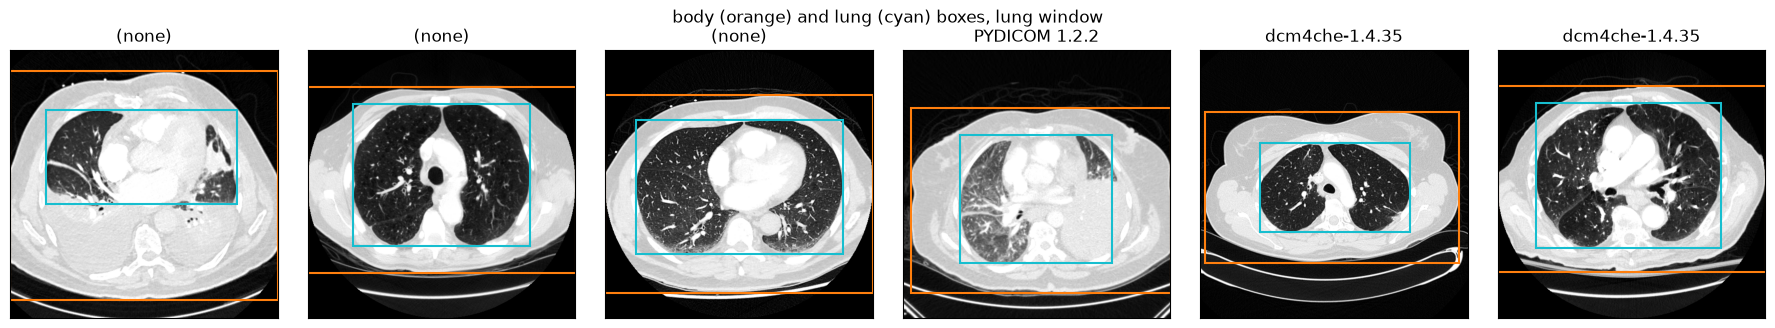

In [23]:
from matplotlib.patches import Rectangle

examples = mid.assign(group=mid["series"].map(series_table["group"])).groupby("group").sample(1, random_state=SEED).head(6)
fig, axes = plt.subplots(1, len(examples), figsize=(3 * len(examples), 3.3))
for ax, r in zip(axes, examples.itertuples()):
    hu = FORMATS["png16"].decode(store_path(store, r.series, r.image).read_bytes()).astype(np.float32) + HU_MIN
    ax.imshow(window(hu, *WINDOWS["lung"]), cmap="gray")
    for (t, b, l, rt), colour in [((r.body_top, r.body_bottom, r.body_left, r.body_right), "tab:orange"),
                                  ((r.lung_top, r.lung_bottom, r.lung_left, r.lung_right), "tab:cyan")]:
        ax.add_patch(Rectangle((l, t), rt - l, b - t, fill=False, color=colour, lw=1.5))
    ax.set(title=r.group.split(" | ")[0], xticks=[], yticks=[])
plt.suptitle("body (orange) and lung (cyan) boxes, lung window")
plt.tight_layout()

### 7.4 Key findings

- **The script gives what this notebook built:** both tables are equal, and there is one file per row and no partial file: 1,937,447 files, 486.1 GB. Every file opens, and the 818 slices compared equal `read_hu` rounded to integer HU.
- **Lung boxes:** median 357 × 247 px (238 × 166 mm) in the middle of the main stacks; 0.5% of those slices have none, 12% of all slices.
- **Body boxes:** the body reaches both sides of the image in 54% of the middle slices, so on those the box spans the whole width.

## Summary

- **Labels:** 1,790,594 slice labels and 7,279 train series with 13 series labels each, no missing value.
- **Slices:** one row per slice, 1,790,594 train and 146,853 test. Series = study = patient.
- **Stacks:** 159 series hold several stacks, and all their positive slices are in the main stack, the only one the models train on. The stacks explain most irregularities of 01; 2 slices at the same position and 34 wide gaps remain, flagged.
- **Folds:** 5 folds of whole series, by iterative stratification; the rare labels differ by at most one series.
- **Hounsfield units:** `read_hu` passes its unit tests and gives the expected values in all 9 storage groups.
- **Store:** PNG 16-bit HU at level 6, one file per slice: lossless, 486 GB, 822 2.5D inputs per second.
- **Saved:** `series.csv`, `slices.csv` and `png16/`, checked against this notebook.

## Limits

- The stack rules were built on the train and the visible test series; the hidden test series may hold other cases. "Only the main stack is labelled" rests on 43 positive series.
- Pixels were compared on 818 of the 1,937,447 slices; the others were only opened without an error.
- The speeds come from 18 series (4,570 slices) on one machine; the minutes per epoch are extrapolated from them.
- The boxes use fixed HU thresholds and were checked only on the table and a few examples, with no reference boxes. Airless lung (consolidation, effusion) can fall outside the lung box, and the body box can include the table.